# Can Chegg finance its own reinvention?

Public-source financial case study by Sulayman Bowles. Evidence cutoff: October 12, 2026. Currency: USD millions. Reported data end June 30; the September debt repayment is a subsequent event. This notebook contains historical calculations and **illustrative scenarios**, not a stock valuation or calendar-quarter forecast.

In [1]:
from model import load_inputs, historical, replacement, run_scenario, write_outputs, serialize
from verify import verify
from decimal import Decimal
from pathlib import Path
import json
inputs = load_inputs()
verify()

Verified: historical FCF/CFO/cash bridges, debt principal distinction, replacement hurdle, equal-margin boundary, all scenario balances, payment timing and investment sensitivities.


## Sources and periods

The source register names the actual statement sections and the limits of each primary source. The approximate $38m reference is June 30 liquidity pro forma for repayment, not a reported September or October cash balance.

In [2]:
register = json.loads(Path('source-register.json').read_text())
for source in register['sources']:
    print(source['id'], source['label'], source['date'])
    print(source['href'])

S1 Chegg FY2025 Form 10-K Year ended 2025-12-31
https://www.sec.gov/Archives/edgar/data/1364954/000136495426000021/chgg-20251231.htm
S2 Chegg Q2 2026 Form 10-Q 2026-08-06
https://www.sec.gov/Archives/edgar/data/1364954/000136495426000088/chgg-20260630.htm
S3 Chegg Q2 2026 earnings release 2026-08-06
https://investor.chegg.com/Press-Releases/press-release-details/2026/Chegg-Reports-Second-Quarter-2026-Earnings/default.aspx
S4 Chegg announces full repayment of convertible notes 2026-09-01
https://investor.chegg.com/Press-Releases/press-release-details/2026/Chegg-Announces-Full-Repayment-of-Convertible-Notes/default.aspx
S5 Chegg FY2025 earnings release 2026-02-09
https://investor.chegg.com/Press-Releases/press-release-details/2026/Chegg-Reports-2025-Fourth-Quarter-and-Full-Year-Financial-Results/default.aspx
S6 Chegg Q1 2026 earnings release 2026-05-06
https://investor.chegg.com/Press-Releases/press-release-details/2026/Chegg-Reports-First-Quarter-2026-Earnings/default.aspx


## The historical cash bridge

Free cash flow improved because lower cash capex exceeded the fall in operating cash flow. Working-capital and restructuring payments are already inside reported CFO; they are not deducted twice.

In [3]:
print(json.dumps(serialize(historical(inputs)), indent=2))

{
  "fcf_h1_2025": "3.791",
  "fcf_h1_2026": "9.461",
  "cfo_change": "-5.525",
  "capex_saving": "11.195",
  "fcf_change": "5.670",
  "fcf_h1_2026_at_h1_2025_capex": "-1.734",
  "cfo_before_working_capital": "26.644",
  "working_capital_change": "-12.483",
  "cash_bridge_ending_including_restricted": "46.254",
  "academic_revenue_loss_q2": "53.588",
  "skilling_revenue_gain_q2": "0.317",
  "skilling_offset_percent": "0.5915503470926326789579756662",
  "skilling_mix_q2_2025_percent": "16.37842465753424657534246575",
  "skilling_mix_q2_2026_percent": "33.81743138729772994657563309",
  "skilling_growth_q2_percent": "1.841203461694836498809316373",
  "academic_decline_q2_percent": "60.96265201415196295917090429",
  "capex_reduction_percent": "70.43095312991506763133060711"
}


## Replacement-growth hurdle

Comparable-period stress using Q2 2026 revenue bases. The 70% academic and 45% skilling contribution margins are **author assumptions**, not disclosed product margins. Equal margins make the revenue and contribution hurdles identical.

In [4]:
for decline in ('0.20','0.30','0.40'):
    print(json.dumps(serialize(replacement(inputs, Decimal(decline))), indent=2))

{
  "academic_decline_percent": "20.00",
  "academic_revenue_lost": "6.86300",
  "skilling_growth_for_flat_revenue_percent": "39.14109729668073457282993042",
  "skilling_growth_for_flat_contribution_percent": "60.88615135039225377995766953"
}
{
  "academic_decline_percent": "30.00",
  "academic_revenue_lost": "10.29450",
  "skilling_growth_for_flat_revenue_percent": "58.71164594502110185924489563",
  "skilling_growth_for_flat_contribution_percent": "91.32922702558838066993650431"
}
{
  "academic_decline_percent": "40.00",
  "academic_revenue_lost": "13.72600",
  "skilling_growth_for_flat_revenue_percent": "78.28219459336146914565986084",
  "skilling_growth_for_flat_contribution_percent": "121.7723027007845075599153391"
}


## Four-quarter liquidity stress

Hypothetical sequential quarters without seasonality. Initial revenue and earnings proxy are calibrated to Q3 guidance midpoints; future rates, capex, conversion drag and the reserve floor are assumptions. This stress test can differ from management's positive second-half cash-flow outlook. Debt payoff is already in the $38m reference; there is no second debt outflow.

In [5]:
print(json.dumps(inputs['stress_test'], indent=2))
results = write_outputs(Path('outputs'))
print(json.dumps(serialize(results['scenarios']), indent=2))

{
  "boundary": "Illustrative four-quarter stress test, not a forecast of reported Chegg quarters. No seasonality. Opening liquidity is management's rounded June 30 pro-forma amount after debt repayment, not observed September/October liquidity. Debt repayment is not deducted again.",
  "reference_opening_liquidity": "38.0",
  "illustrative_reserve_floor": "25.0",
  "starting_academic_revenue": "26.0",
  "starting_skilling_revenue": "17.5",
  "starting_earnings_proxy": "1.5",
  "academic_contribution_margin": "0.70",
  "skilling_contribution_margin": "0.45",
  "quarterly_cash_capex": "3.0",
  "quarterly_cash_conversion_drag": "0.5",
  "first_quarter_severance": "1.2",
  "calibration": "Starting revenue and earnings proxy equal midpoints of Q3 management guidance. Product split, contribution margins, cash costs, payment timing and reserve floor are author assumptions, not disclosed product margins or liquidity guidance. The earnings proxy is not reported adjusted EBITDA."
}
[
  {
    "s

## Publication figures

Figures retain matching periods, units and their observed-versus-modeled boundaries. The scenario chart is not a trajectory of reported company cash balances.

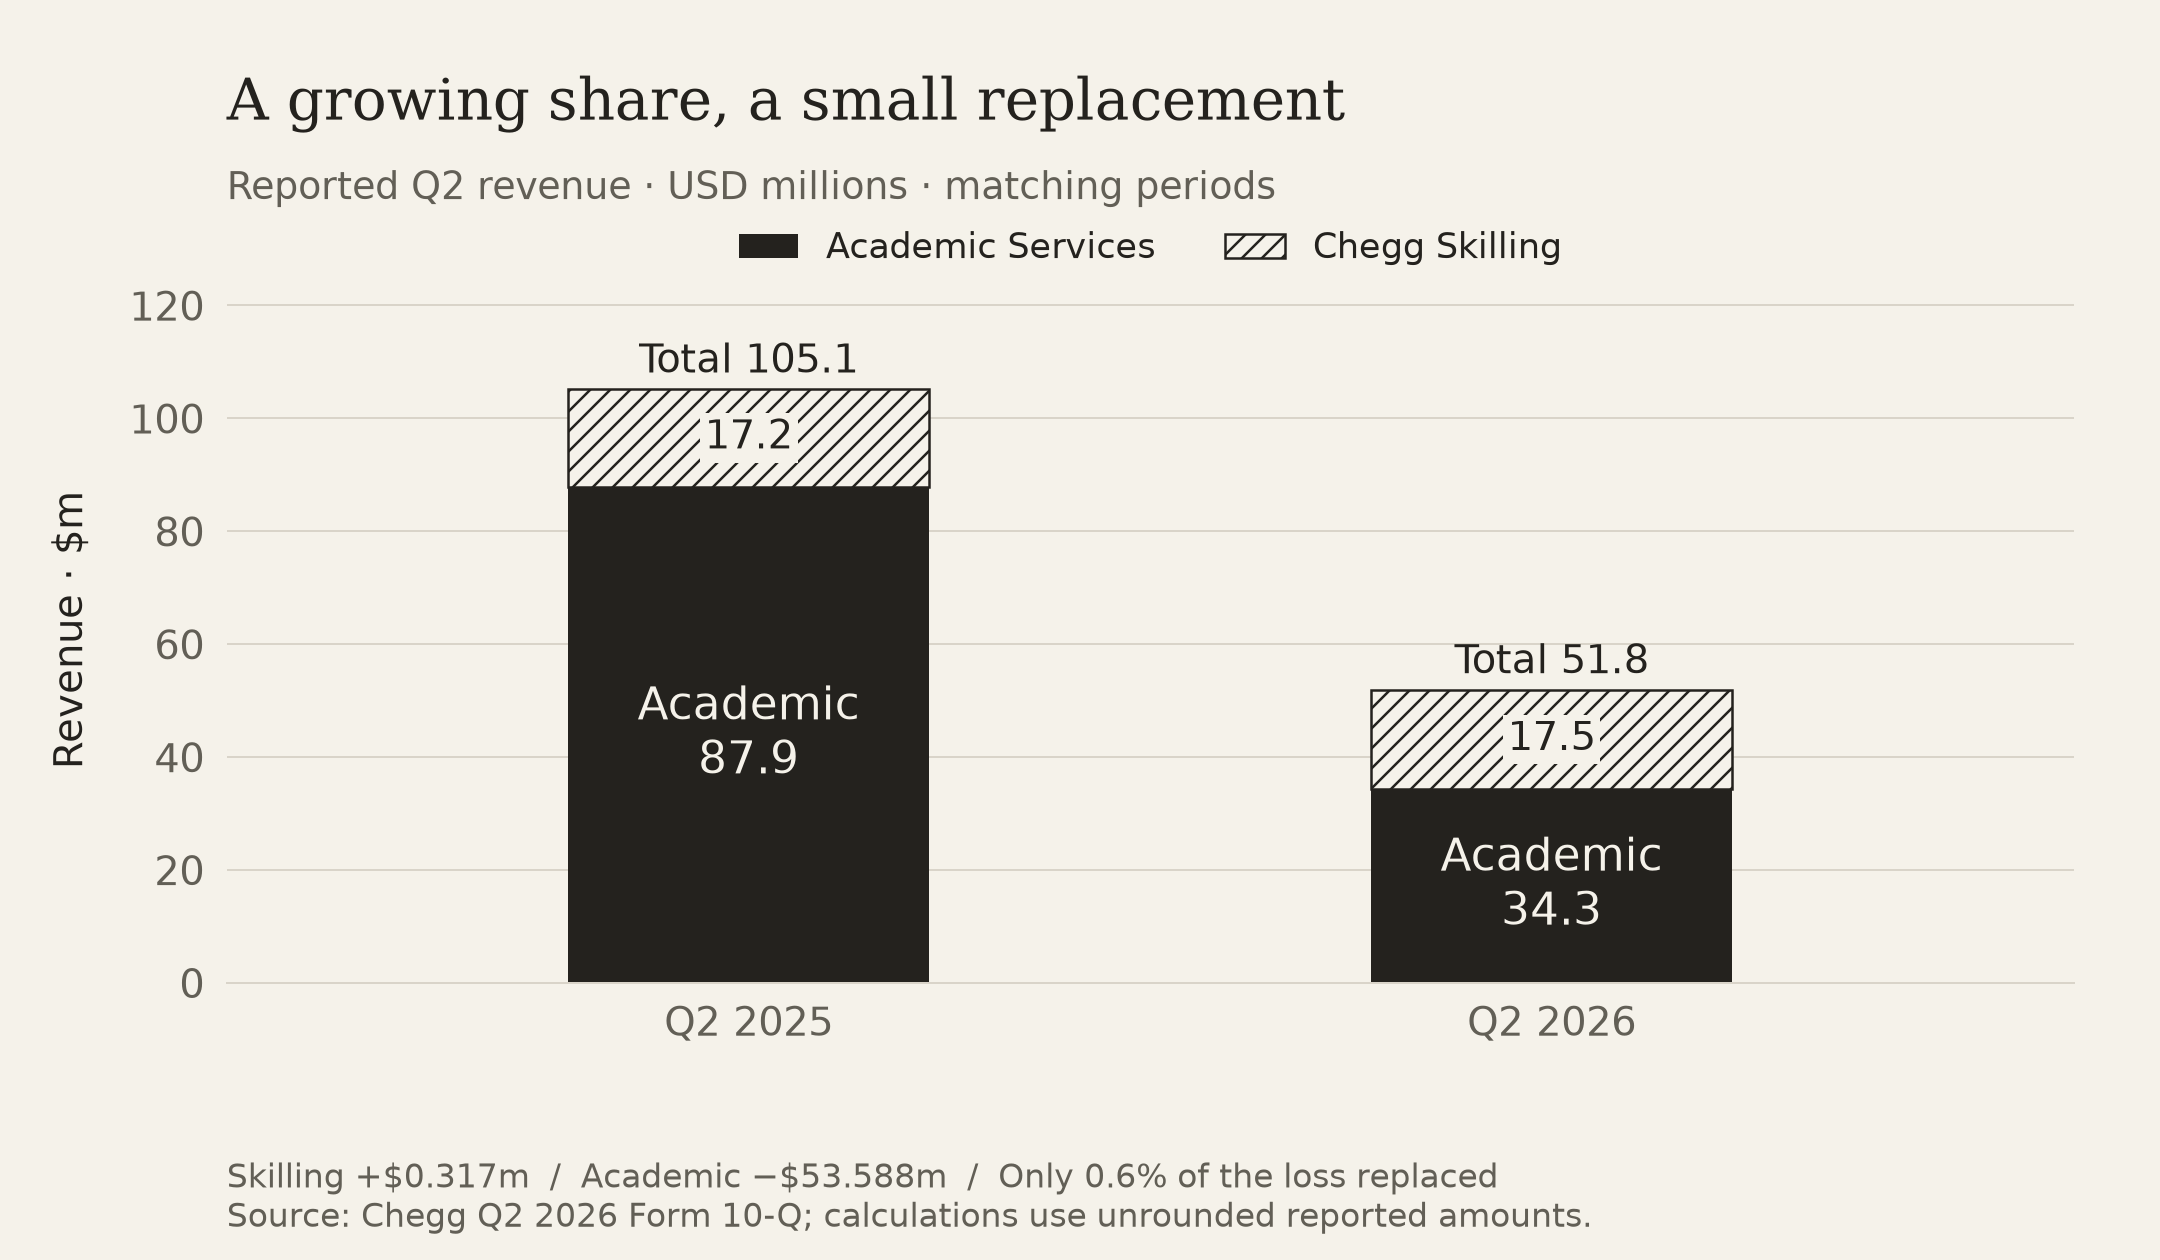

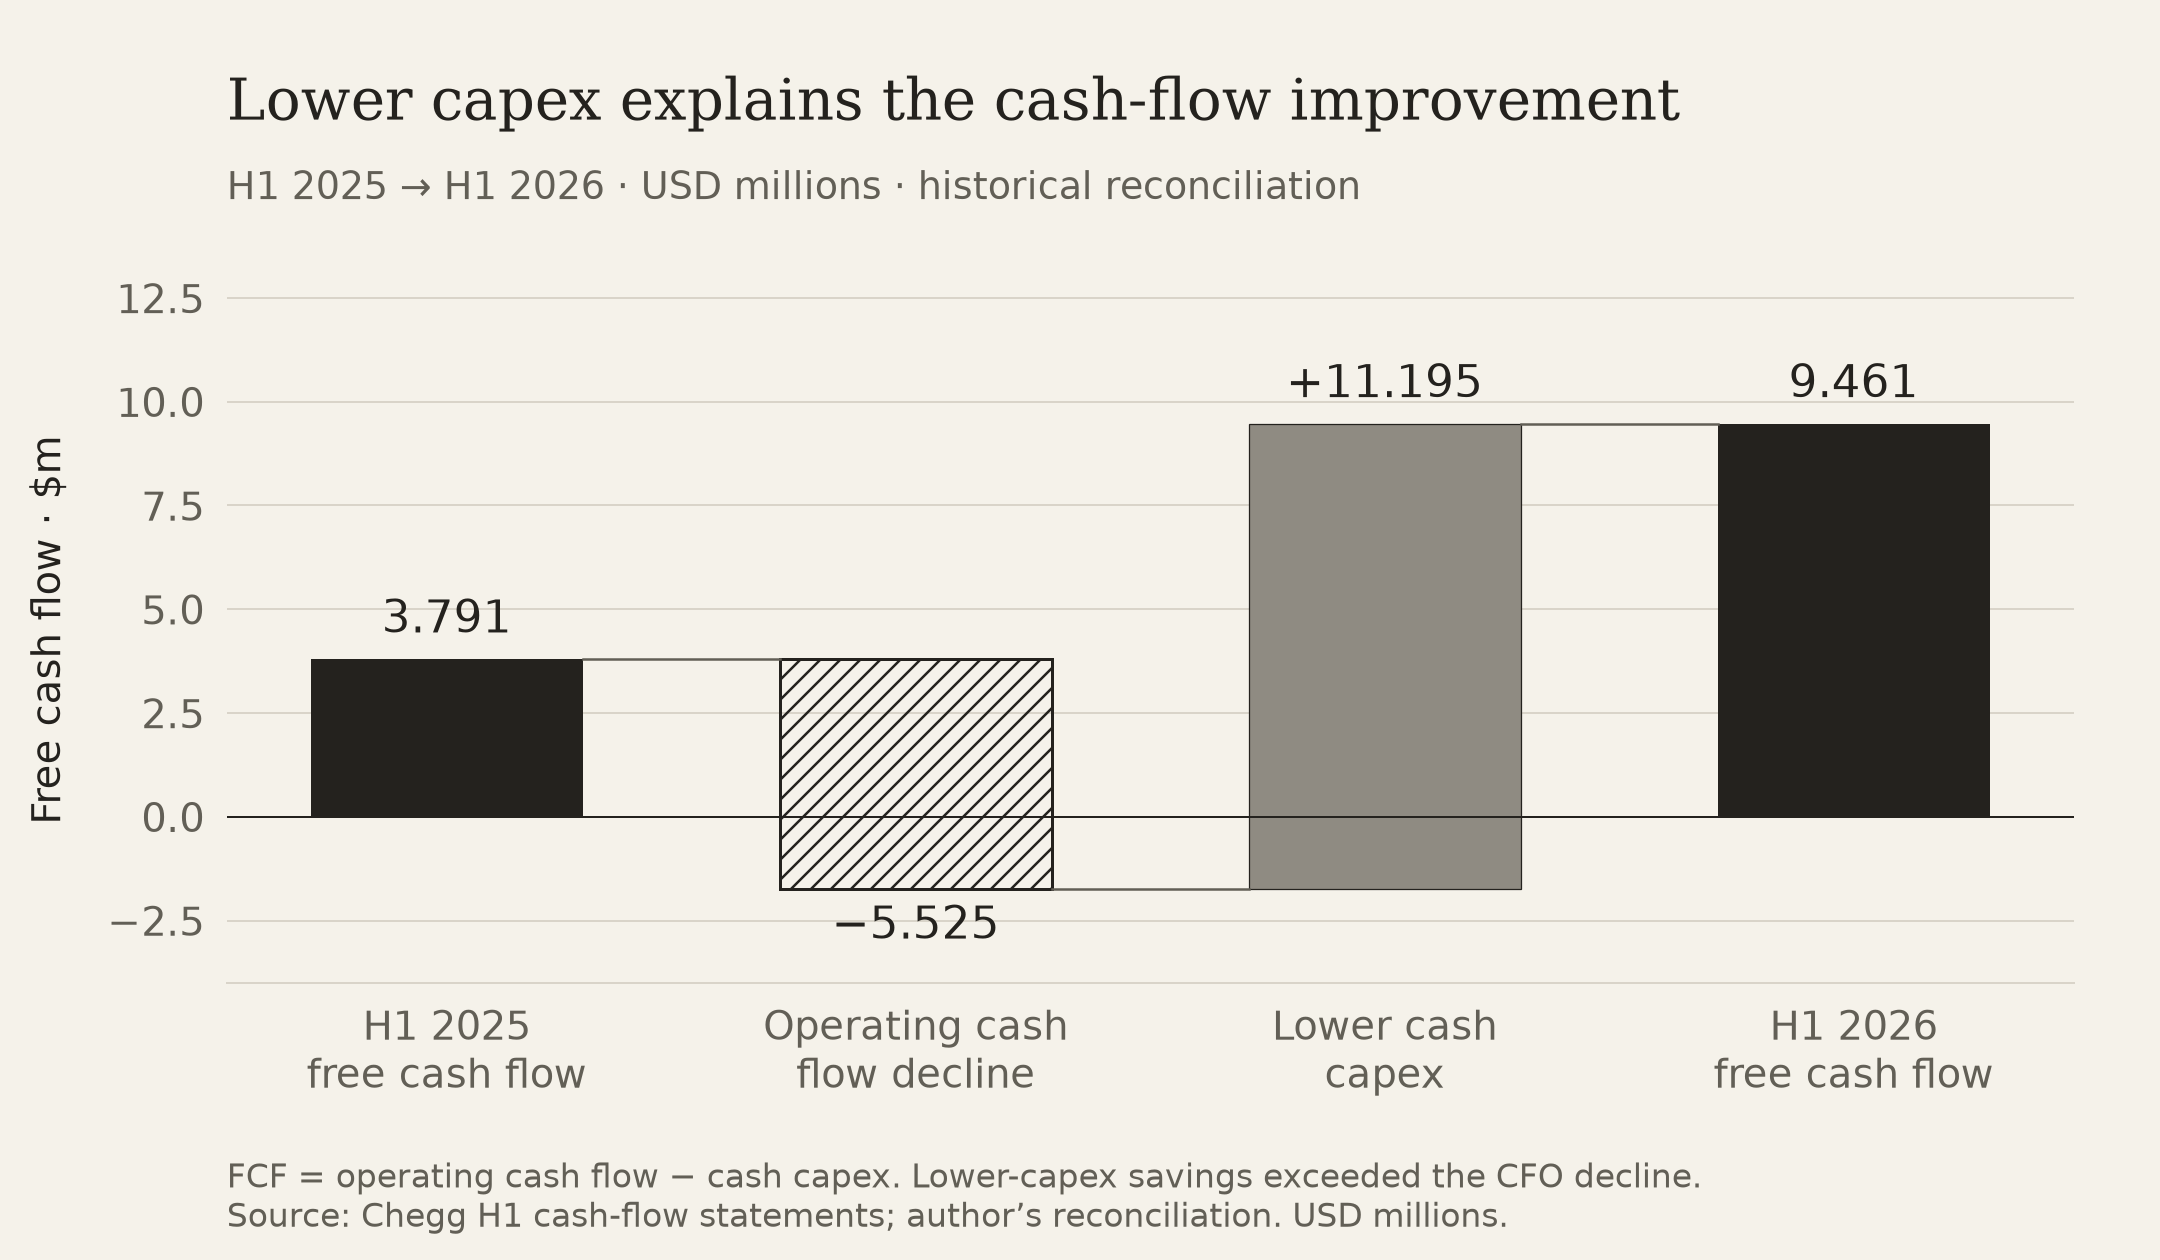

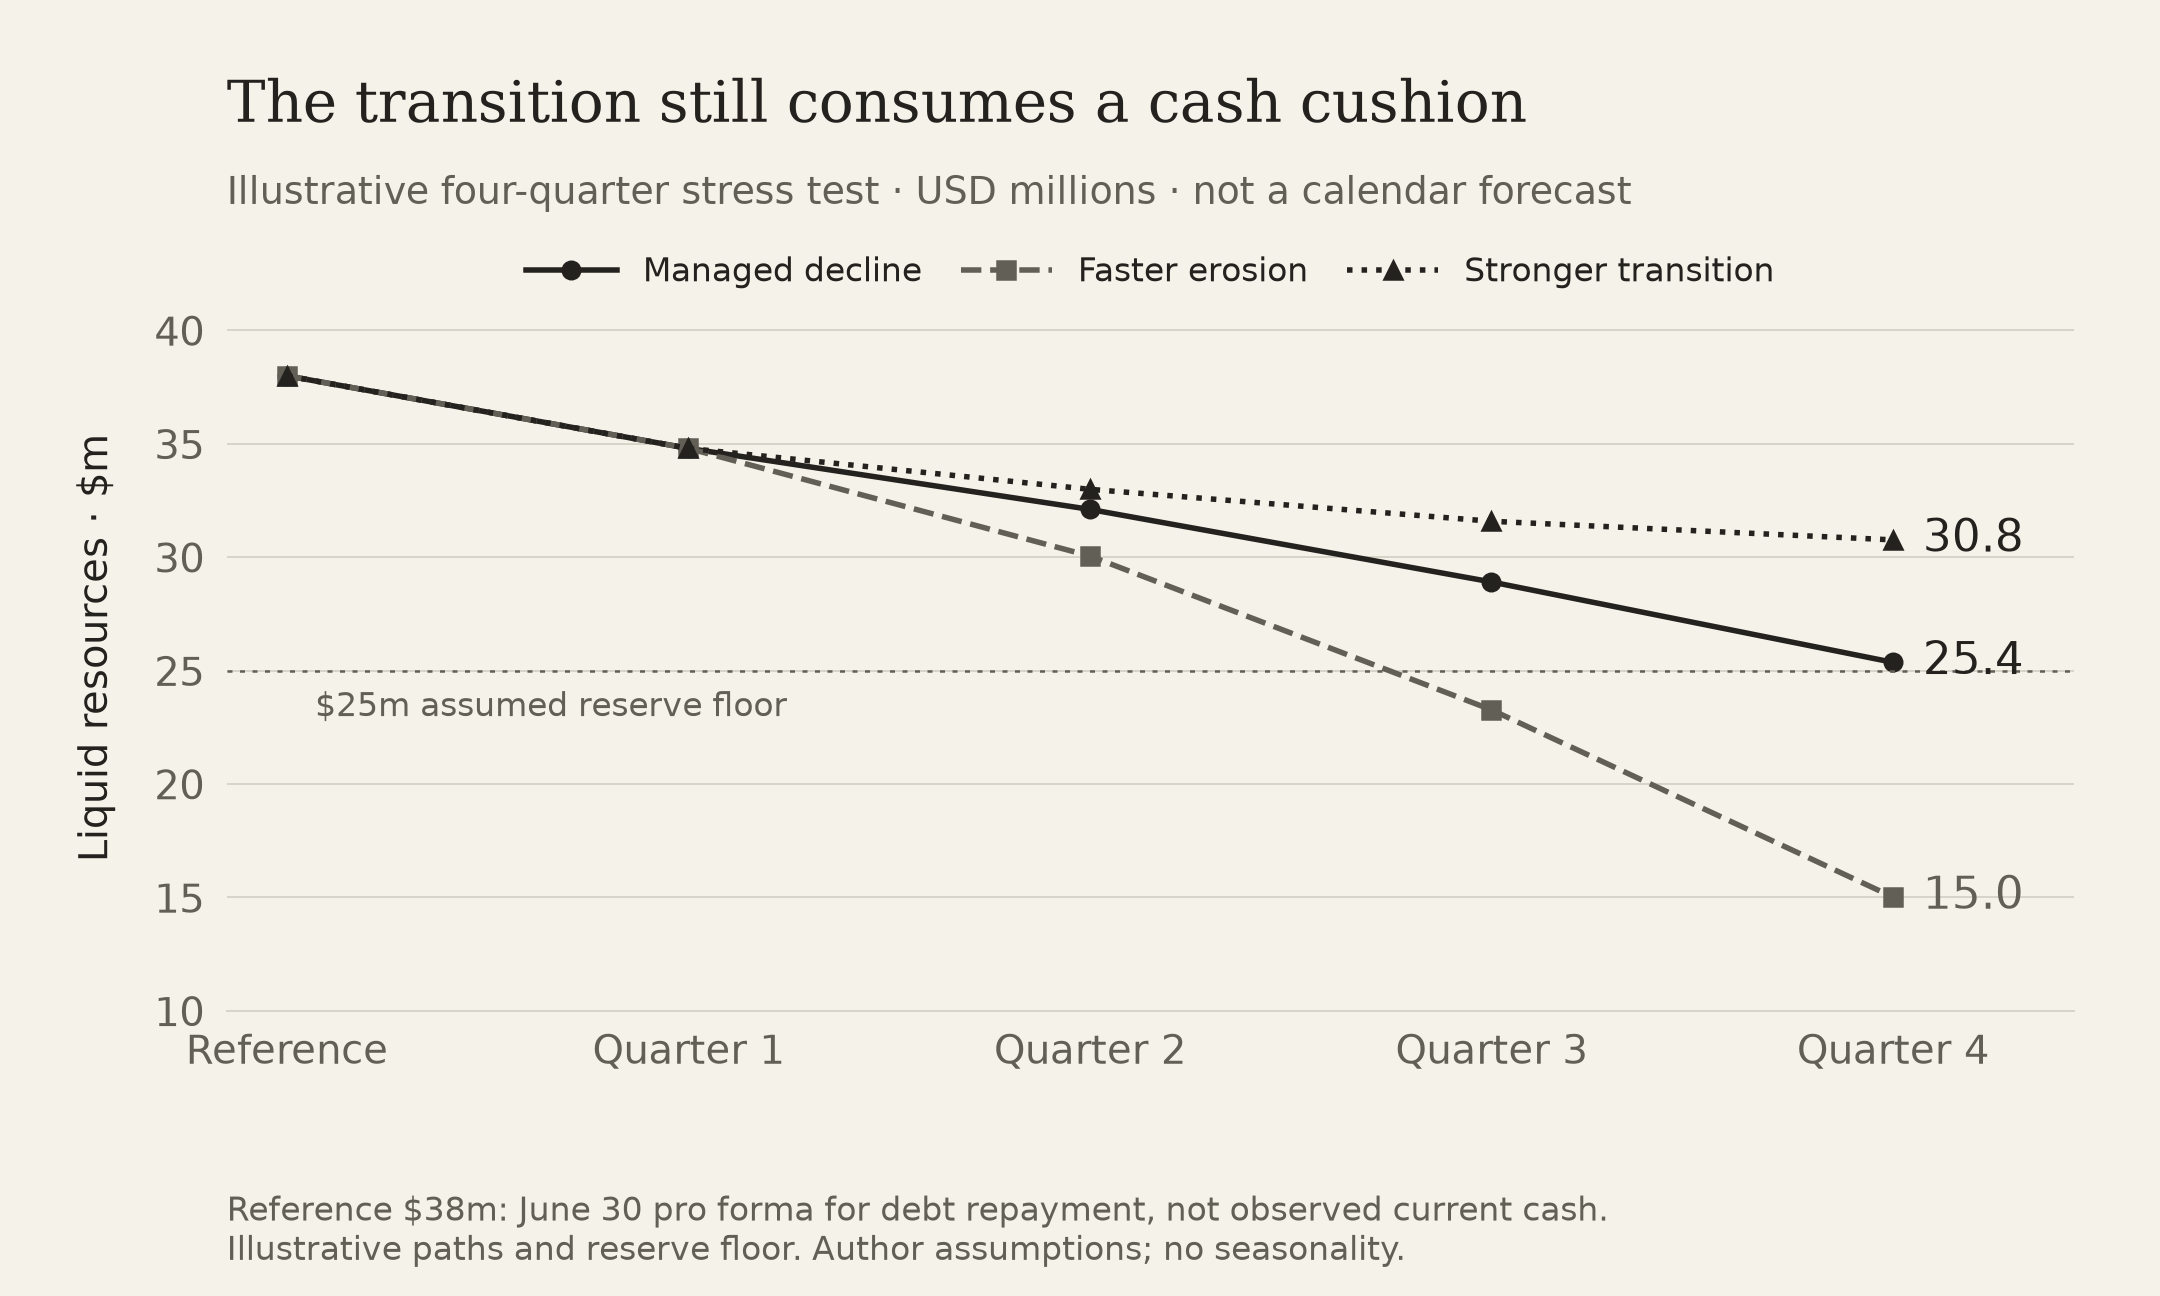

In [6]:
from figures import build_figures
from IPython.display import Image, display
build_figures()
for name in ('chegg-revenue-replacement','chegg-free-cash-flow-bridge','chegg-liquidity-stress-test'):
    display(Image(filename='figures/' + name + '.png'))

## Use the model

Edit `inputs.json`, then rerun all cells. Each extra $1m of quarterly capex reduces four-quarter ending liquidity by $4m if other assumptions stay fixed. The verification checks this sensitivity and the one-time-spending boundary independently. A model reserve breach is a decision signal, not proof of insolvency.